In [14]:
import os
os.chdir('/home/hedi/HSCNG/')
import numpy as np
from astropy.io import fits
from astropy.coordinates import SkyCoord
from astropy.wcs import WCS
from astropy import units as u
import matplotlib.pyplot as plt
import pprint
import pymaster as nmt
from hsc_y3_utils import stats_code
from hsc_y3_utils import map_utils
import tqdm

In [25]:
name_fields = ['XMM', 'VVDS','GAMA09H', 'GAMA15H', 'WIDE12H', 'HECTOMAP']
number_patches= [8, 25,23,7,26,13] # of each corresponding field

field = 'GAMA09H'
tomo_bin = [1, 2, 3, 4]         # tomo_bin, 0 is excluded.
n_patch = 4

dat = fits.getdata(f'data/real/hscy3_shape_chopped_{field}_{n_patch}.fits')
dat = dat[np.isin(dat['hsc_y3_zbin'], tomo_bin)]

# WCS

In [26]:
# --- Input RA/Dec Range (degrees) ---
ra = dat['i_ra']
dec = dat['i_dec']
padding = 10  # pixels

ra_min, ra_max = ra.min(), ra.max()
dec_min, dec_max =  dec.min(), dec.max()

# --- Pixel scale ---
pixscale_deg = 0.5 / 60.0   # 0.5 arcmin → degrees/pixel

# --- Compute image size ---
# RA range needs cos(dec) correction for actual sky distance.
dec_center = 0.5 * (dec_min + dec_max)
ra_center = 0.5 * (ra_min + ra_max)

# ra_corr_range = (ra_max - ra_min) * np.cos(np.deg2rad(dec_center))
# dec_range = dec_max - dec_min


# nx = int(np.ceil(ra_corr_range / pixscale_deg))
# ny = int(np.ceil(dec_range / pixscale_deg))

# --- Build WCS ---
w = WCS(naxis=2)

w.wcs.crpix = [0, 0]
# Set reference coordinates (center RA/Dec)
w.wcs.crval = [ra_center, dec_center]

# Set scale: CDELT is negative in RA to follow standard astro convention
w.wcs.cdelt = [-pixscale_deg, pixscale_deg]

# Use standard TAN projection
w.wcs.ctype = ["RA---TAN", "DEC--TAN"]

w.wcs.cunit = ['deg', 'deg']


pos = w.world_to_pixel(SkyCoord(ra=ra*u.deg, dec=dec*u.deg))

xx = pos[0]
yy = pos[1]

xmin, xmax, ymin, ymax = xx.min(), xx.max(), yy.min(), yy.max()

nx = int(xmax - xmin) + padding * 2
ny = int(ymax - ymin) + padding * 2


w.wcs.crpix = [-xmin + padding, -ymin + padding]

print("Image size:", nx, "x", ny)
print(w)

Image size: 383 x 382
WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN' 'DEC--TAN'
CUNIT : 'deg' 'deg'
CRVAL : 132.6927102109912 2.594004390929169
CRPIX : 192.87242836496407 192.45557146209273
PC1_1 PC1_2  : 1.0 0.0
PC2_1 PC2_2  : 0.0 1.0
CDELT : -0.008333333333333333 0.008333333333333333
NAXIS : 0  0


# shear map

In [27]:
flatgrid = map_utils.FlatClass(wcs=w, nx=nx, ny=ny)
pix = flatgrid.pos2pix(ra=dat['i_ra'], dec=dat['i_dec'])
ra_cat=dat['i_ra']
dec_cat=dat['i_dec']
weight_cat = dat['i_hsmshaperegauss_derived_weight']
m_cat = dat['i_hsmshaperegauss_derived_shear_bias_m']
erms_cat = dat['i_hsmshaperegauss_derived_rms_e']

e1_cat, e2_cat = dat['i_hsmshaperegauss_e1'], dat['i_hsmshaperegauss_e2']
c1_cat, c2_cat = dat['i_hsmshaperegauss_derived_shear_bias_c1'], dat['i_hsmshaperegauss_derived_shear_bias_c2']
flux_cat = dat['i_apertureflux_10_mag']
res_cat = dat['i_hsmshaperegauss_resolution']

psf11, psf12, psf22 = dat['i_sdssshape_psf_shape11'], dat['i_sdssshape_psf_shape12'], dat['i_sdssshape_psf_shape22']
epsf1_cat   = (psf11-psf22)/(psf11+psf22)
epsf2_cat   = (2*psf12)/(psf11+psf22)

# all kinds of calibrations and selection effect corrections
e1_hat, e2_hat =  map_utils.calib_shear_y3(weight_cat, m_cat, erms_cat, e1_cat, e2_cat, c1_cat, c2_cat, flux_cat, res_cat, epsf1_cat, epsf2_cat)

# weighted averaged shear map

In [28]:
flatgrid = map_utils.FlatClass(wcs=w, nx=nx, ny=ny)
pix = flatgrid.pos2pix(ra=dat['i_ra'], dec=dat['i_dec'])
ra_cat=dat['i_ra']
dec_cat=dat['i_dec']
weight_cat = dat['i_hsmshaperegauss_derived_weight']
m_cat = dat['i_hsmshaperegauss_derived_shear_bias_m']
erms_cat = dat['i_hsmshaperegauss_derived_rms_e']

e1_cat, e2_cat = dat['i_hsmshaperegauss_e1'], dat['i_hsmshaperegauss_e2']
c1_cat, c2_cat = dat['i_hsmshaperegauss_derived_shear_bias_c1'], dat['i_hsmshaperegauss_derived_shear_bias_c2']
flux_cat = dat['i_apertureflux_10_mag']
res_cat = dat['i_hsmshaperegauss_resolution']

psf11, psf12, psf22 = dat['i_sdssshape_psf_shape11'], dat['i_sdssshape_psf_shape12'], dat['i_sdssshape_psf_shape22']
epsf1_cat   = (psf11-psf22)/(psf11+psf22)
epsf2_cat   = (2*psf12)/(psf11+psf22)

# all kinds of calibrations and selection effect corrections
e1_hat, e2_hat =  map_utils.calib_shear_y3(weight_cat, m_cat, erms_cat, e1_cat, e2_cat, c1_cat, c2_cat, flux_cat, res_cat, epsf1_cat, epsf2_cat)

# weighted averaged shear map

# kappa map

In [33]:
smooth_g = False
inpainting = True
smooth_k = True
procedure = []

if smooth_g:
    procedure.append('smooth g')
if inpainting:
    procedure.append('inpainting')
procedure.append('KSI-masking')
if smooth_k:
    procedure.append('smooth k')

procedure_str = '-'.join(procedure)

In [34]:
# pixelize shear map
[g1_map, g2_map], [mask, nmap] = map_utils.create_shear_map(ra_cat, dec_cat, e1_hat, e2_hat, flatgrid, weights=weight_cat)
# questions here: the mask shows whether there is galaxy, but we dont use the weight map afterwards.
mask_z = flatgrid.transform_mapsize(mask)
g1_map = flatgrid.transform_mapsize(g1_map)
g2_map = flatgrid.transform_mapsize(g2_map)

smoothing_kernel_size = 3  # arcmin
smoothing_pixels = smoothing_kernel_size / (pixscale_deg * 60)

# smoothing
if smooth_g:
    g1_map = flatgrid.smooth_G(g1_map, smoothing_pixels)      # smoothed g1 map, 2d
    g2_map = flatgrid.smooth_G(g2_map, smoothing_pixels)
if inpainting:
# Inpainting
    g1_map = map_utils.inpaint(g1_map*mask_z, mask_z, niter=100, thresholding='hard')
    g2_map = map_utils.inpaint(g2_map*mask_z, mask_z, niter=100, thresholding='hard')

# KS inversion
kappa, kappa_i = map_utils.KS_map(g1_map, g2_map)

# masking
kappa *= mask_z
kappa_i *= mask_z

if smooth_k:
    kappa = flatgrid.smooth_G(kappa.flatten(), smoothing_pixels)          # E mode
    kappa_i = flatgrid.smooth_G(kappa_i.flatten(), smoothing_pixels)      # B mode

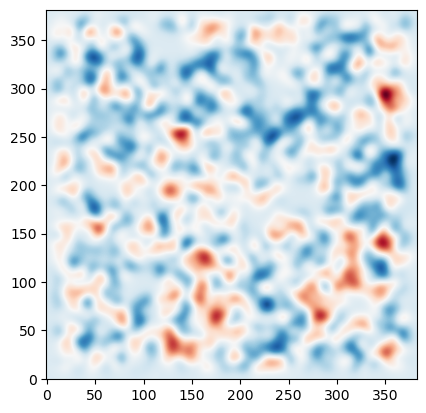

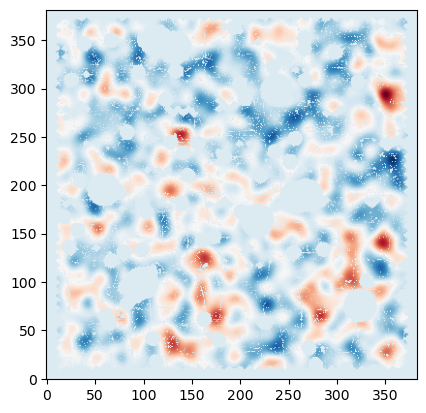

In [37]:
plt.imshow(kappa, origin='lower', cmap='RdBu_r')
plt.show()
plt.imshow(kappa*mask_z, origin='lower', cmap='RdBu_r')
plt.show()

# power spectrum

In [38]:
size_rad_x = pixscale_deg / 180.0 * np.pi * nx
size_rad_y = pixscale_deg / 180.0 * np.pi * ny

f0 = nmt.NmtFieldFlat(size_rad_x, size_rad_y, mask_z, [kappa]) 

In [39]:
np.pi * 2 / max(size_rad_y, size_rad_x)

112.79373368146214

In [40]:
np.pi / np.radians(pixscale_deg)

np.float64(21600.0)

In [41]:
size_rad_x = pixscale_deg / 180.0 * np.pi * nx
size_rad_y = pixscale_deg / 180.0 * np.pi * ny
ell_edges = np.geomspace(300, 10000, 10)

# ell_edges = np.arange(0, 5000, 200)
bins = nmt.bins.NmtBinFlat(ell_edges[:-1], ell_edges[1:])
# C_gg = stats_code.compute_power_spectrum_spin2(g1_smoothed, g2_smoothed, mask.reshape(ny, nx), size_rad_x, size_rad_y, bins)
f0 = nmt.NmtFieldFlat(size_rad_x, size_rad_y, mask_z, [kappa]) 

#Compute workspace if needed
wsp=nmt.NmtWorkspaceFlat()
wsp.compute_coupling_matrix(f0,f0,bins)

EE, BB, EB = stats_code.compute_ps_spin0_all_terms(kappa, kappa_i, mask.reshape(ny, nx), size_rad_x, size_rad_y, bins, wsp)
ls = ell_edges[:-1] + np.diff(ell_edges)/2

Text(0.5, 1.0, 'Field: GAMA09H, inpainting-KSI-masking-smooth k')

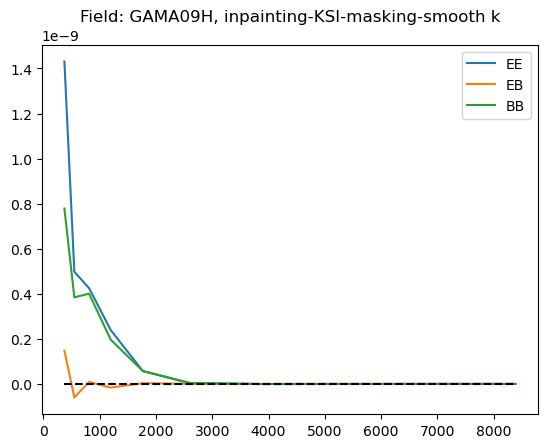

In [42]:
plt.plot(ls, EE, linestyle='-', label='EE')
plt.plot(ls, EB, linestyle='-', label='EB')
plt.plot(ls, BB, linestyle='-', label='BB')

plt.hlines(0, xmin=ls.min(), xmax=ls.max(), colors='k', linestyles='dashed')

plt.legend()

plt.title(f'Field: {field}, {procedure_str}')

# plt.savefig(f'Cll_fig {procedure_str}.pdf')

In [43]:
N_rand = 100
rand_EE = []
rand_BB = []
rand_EB = []

for i in tqdm.trange(N_rand):
    shear_random = map_utils.random_rotation(e1_hat, e2_hat)        # random rotate the shear.

    # weighted averaged shear map
    [g1_map_r, g2_map_r], [mask, nmap] = map_utils.create_shear_map(ra_cat,dec_cat, *shear_random, flatgrid, weights= weight_cat)

    # questions here: the mask shows whether there is galaxy, but we dont use the weight map afterwards.

    mask_z = flatgrid.transform_mapsize(mask)
    g1_map_r = flatgrid.transform_mapsize(g1_map_r)
    g2_map_r = flatgrid.transform_mapsize(g2_map_r)

    smoothing_kernel_size = 3  # arcmin
    smoothing_pixels = smoothing_kernel_size / (pixscale_deg * 60)

    if smooth_g:
        g1_map_r = flatgrid.smooth_G(g1_map_r, smoothing_pixels)      # smoothed g1 map, 2d
        g2_map_r = flatgrid.smooth_G(g2_map_r, smoothing_pixels)
    if inpainting:
    # Inpainting
        g1_map_r = map_utils.inpaint(g1_map_r*mask_z, mask_z, niter=100, thresholding='hard')
        g2_map_r = map_utils.inpaint(g2_map_r*mask_z, mask_z, niter=100, thresholding='hard')  # what if we subs mask with weight map?

    kappa_r, kappa_i_r= map_utils.KS_map(g1_map_r, g2_map_r)
    kappa_r *= mask_z
    kappa_i_r *= mask_z

    if smooth_k:
        kappa_r = flatgrid.smooth_G((kappa_r * mask_z).flatten(), smoothing_kernel_size)          # E mode
        kappa_i_r = flatgrid.smooth_G((kappa_i_r * mask_z).flatten(), smoothing_kernel_size)      # B mode

    # work space calculation is done before hand.

    EE_r, BB_r, EB_r = stats_code.compute_ps_spin0_all_terms(kappa_r, kappa_i_r, mask.reshape(ny, nx), size_rad_x, size_rad_y, bins, wsp)

    rand_EE.append(EE_r)
    rand_BB.append(BB_r)
    rand_EB.append(EB_r)

rand_EE = np.array(rand_EE)
rand_BB = np.array(rand_BB)
rand_EB = np.array(rand_EB)


EE_rm = rand_EE.mean(axis=0)
EE_std = rand_EE.std(axis=0)
BB_rm = rand_BB.mean(axis=0)
BB_std = rand_BB.std(axis=0)
EB_rm = rand_EB.mean(axis=0)
EB_std = rand_EB.std(axis=0)

100%|██████████| 100/100 [07:06<00:00,  4.26s/it]


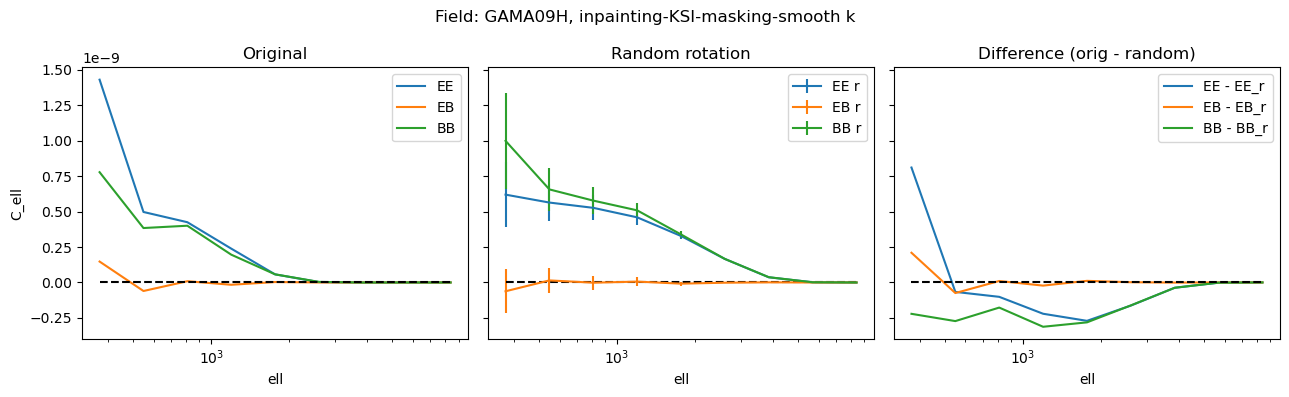

In [44]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharey=True)

fig.suptitle(f'Field: {field}, {procedure_str}')
# original
axs[0].plot(ls, EE, '-', label='EE')
axs[0].plot(ls, EB, '-', label='EB')
axs[0].plot(ls, BB, '-', label='BB')
axs[0].hlines(0, ls.min(), ls.max(), colors='k', linestyles='--')
axs[0].set_title('Original')
axs[0].legend()
axs[0].set_xlabel('ell')
axs[0].set_ylabel('C_ell')
axs[0].semilogx()

# random
axs[1].errorbar(ls, EE_rm, EE_std, label='EE r')
axs[1].errorbar(ls, EB_rm, EB_std, label='EB r')
axs[1].errorbar(ls, BB_rm, BB_std, label='BB r')
axs[1].hlines(0, ls.min(), ls.max(), colors='k', linestyles='--')
axs[1].set_title('Random rotation')
axs[1].legend()
axs[1].set_xlabel('ell')
axs[1].semilogx()

# subtracted
axs[2].plot(ls, EE - EE_rm, '-', label='EE - EE_r')
axs[2].plot(ls, EB - EB_rm, '-', label='EB - EB_r')
axs[2].plot(ls, BB - BB_rm, '-', label='BB - BB_r')
axs[2].hlines(0, ls.min(), ls.max(), colors='k', linestyles='--')
axs[2].set_title('Difference (orig - random)')
axs[2].legend()
axs[2].set_xlabel('ell')
# axs[2].set_ylim(-2e-9, 3.5e-9)
axs[2].semilogx()

plt.tight_layout()

plt.savefig(f'figs/All_Cll_{field}_{n_patch}_{procedure_str}.pdf')
plt.show()